# Which motif sites are bound, in which cell type?

A motif match in open chromatin is a *candidate* binding site.
`epi.tl.tf_binding` scores every candidate for occupancy by its factor, in
every cell type. Its default (`method='occupancy'`) is a thermodynamic
motif-accessibility score:

$$\text{score}_i = \log \sum_{j:\,|c_j-c_i|\le 150} \underbrace{(1 + n_j + 2\,n_j^{\text{short}})}_{\text{accessibility}}\;\underbrace{e^{\beta s_j}}_{\text{motif affinity}}$$

* $n_j$: Tn5 insertions within ±50 bp of site $j$; $n_j^{\text{short}}$ those from
  sub-nucleosomal fragments (≤ 120 bp), which come from nucleosome-free DNA;
* $s_j$: the motif's log-odds score at the site, $\beta = 0.5$;
* the sum runs over the same motif's sites within ±150 bp.

With the factor scarce, occupancy is accessibility times the Boltzmann weight of
binding. There is no training and no Tn5 bias model, so the score runs in one pass
over the fragments file, in seconds. Against ENCODE ChIP-seq it ranks bound sites
better than footprint scores (median AUROC 0.89-0.91 in four cell types, PRINT
0.72-0.77; `tests/parity/tf_binding/`).

This tutorial applies it to the 10x PBMC 10k Multiome sample, the data of
[t_print_footprint](t_print_footprint.ipynb) and [t_seq2print](t_seq2print.ipynb):

1. candidate sites of 17 TFs in peaks of seven cell types;
2. scores per cell type, at equal sequencing depth;
3. which factor is bound in which cell type;
4. the sites a factor binds in one cell type and not another, and the genes
   they sit next to.

## Part 1 · Setup

In [1]:
%matplotlib inline
import os, sys, pathlib, re, gzip, time, warnings
warnings.filterwarnings('ignore', module='tqdm')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad


def _find_repo(start):
    p = pathlib.Path(start).resolve()
    for cand in (p, *p.parents):
        if (cand / 'epione' / '__init__.py').exists():
            return cand
    return None


CODE = (pathlib.Path(os.environ['EPIONE_SRC']) if os.environ.get('EPIONE_SRC')
        else _find_repo(pathlib.Path.cwd()))
if CODE is not None:
    sys.path.insert(0, str(CODE))

import epione as epi

# EPIONE_TUTORIAL_DATA picks the folder; the default is epione's pooch cache.
DATA = os.environ.get('EPIONE_TUTORIAL_DATA')
files = epi.datasets.pbmc10k_multiome_atac(pathlib.Path(DATA) / 'pbmc10k_multiome' if DATA else None)
FASTA = str(epi.data.hg38.fasta)
WORK = files['fragments'].parent / 'tf_binding_work'; WORK.mkdir(exist_ok=True)
N_JOBS = int(os.environ.get('SLURM_CPUS_PER_TASK', 8))

epi.pl.plot_set()
TYPES = ['CD14 Mono', 'CD16 Mono', 'DC', 'B', 'CD4 T', 'CD8 T', 'NK']
# the same colour per cell type as t_print_footprint and t_seq2print (from epi.pl.sc_color)
TCOL = dict(zip(TYPES, ['#EF7B77', '#941456', '#FCBC10', '#279AD7', '#368650', '#7CBB5F', '#5E4D9A']))

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Part 2 · Cells and cell types

scGLUE's copy of this sample carries Seurat-WNN cell types (from RNA and ATAC
together). We merge them into seven groups and drop the small T-cell subsets
(MAIT, γδ T) and progenitors. `tf_binding` reads the fragments file named in
`adata.uns['files']`, so an AnnData with cell barcodes and labels is all it needs.

In [2]:
COARSE = {'CD14 Mono': 'CD14 Mono', 'CD16 Mono': 'CD16 Mono', 'cDC': 'DC', 'pDC': 'DC',
          'Naive B': 'B', 'Intermediate B': 'B', 'Memory B': 'B', 'Plasma': 'B',
          'CD4 Naive': 'CD4 T', 'CD4 TCM': 'CD4 T', 'CD4 TEM': 'CD4 T', 'Treg': 'CD4 T',
          'CD8 Naive': 'CD8 T', 'CD8 TEM_1': 'CD8 T', 'CD8 TEM_2': 'CD8 T', 'NK': 'NK'}
obs = ad.read_h5ad(files['atac'], backed='r').obs[['cell_type', 'nCount_ATAC']].copy()
obs['celltype'] = obs['cell_type'].map(COARSE)
obs = obs[obs['celltype'].notna()]
obs['celltype'] = pd.Categorical(obs['celltype'], TYPES)
adata = ad.AnnData(obs=obs)
adata.uns['files'] = {'fragments': str(files['fragments'])}
depth = obs.groupby('celltype', observed=True)['nCount_ATAC'].agg(cells='size', counts='sum')
depth['counts'] = (depth['counts'] / 1e6).round(1)
depth = depth.rename(columns={'counts': 'ATAC counts in peaks (M)'})
depth.T

celltype,CD14 Mono,CD16 Mono,DC,B,CD4 T,CD8 T,NK
cells,2554.0,442.0,278.0,735.0,2938.0,1991.0,403.0
ATAC counts in peaks (M),56.0,9.3,8.5,17.4,55.1,38.6,7.5


## Part 3 · Peaks and candidate sites

Peaks are called in each cell type and merged (`epi.single.call_peaks`, cached).
Candidate sites are matches of 17 JASPAR 2024 motifs in the peaks, found with MOODS
(`epi.tl.hint_match_motifs`, false-positive rate 5 × 10⁻⁵); the `score` column is the
log2-odds the occupancy score uses. The panel covers the main lineages:

* myeloid: C/EBPα and β, PU.1 (SPI1), IRF8, KLF4, MAFB;
* B cells: EBF1, PAX5, OCT2 (POU2F2);
* T cells: TCF7, LEF1, GATA3, RUNX3;
* NK and cytotoxic T cells: T-bet (TBX21), EOMES;
* bound in every cell type: CTCF, NRF1.

In [3]:
%%time
peak_file = WORK / 'peaks_celltype.tsv'
if peak_file.exists():
    peaks = pd.read_csv(peak_file, sep='\t')
else:
    peaks = epi.single.call_peaks(adata, groupby='celltype', genome=epi.data.hg38, inplace=False,
                                  verbose=False)
    peaks.to_csv(peak_file, sep='\t', index=False)

MEME = WORK / 'JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt'
if not MEME.exists():
    import urllib.request
    urllib.request.urlretrieve('https://jaspar.elixir.no/download/data/2024/CORE/' + MEME.name, MEME)
jaspar = {}
for k, v in epi.models.grelu.read_meme(MEME).items():       # 'MA0102.5 CEBPA' -> [4, w]
    jaspar.setdefault(k.split()[1].upper(), v)

PANEL = {'myeloid': ['CEBPA', 'CEBPB', 'SPI1', 'IRF8', 'KLF4', 'MAFB'],
         'B cell': ['EBF1', 'PAX5', 'POU2F2'],
         'T cell': ['TCF7', 'LEF1', 'GATA3', 'RUNX3'],
         'NK / cytotoxic': ['TBX21', 'EOMES'],
         'every cell': ['CTCF', 'NRF1']}
TFS = [tf for tfs in PANEL.values() for tf in tfs]
sites = epi.tl.hint_match_motifs(peaks[['chrom', 'start', 'end']],
                                 {tf: (jaspar[tf] * 100).round().tolist() for tf in TFS},
                                 FASTA, fpr=5e-5)
sites = (sites.rename(columns={'name': 'tf'}).drop_duplicates(['tf', 'chrom', 'start', 'end'])
              .reset_index(drop=True))
print(f'{len(peaks):,} peaks, {len(sites):,} candidate sites')
sites['tf'].value_counts().reindex(TFS).rename('sites').to_frame().T

138,986 peaks, 288,738 candidate sites
CPU times: user 2.44 s, sys: 303 ms, total: 2.75 s
Wall time: 2.82 s


tf,CEBPA,CEBPB,SPI1,IRF8,KLF4,MAFB,EBF1,PAX5,POU2F2,TCF7,LEF1,GATA3,RUNX3,TBX21,EOMES,CTCF,NRF1
sites,15425,3456,64634,13844,45327,9154,15008,2482,14736,10237,8331,7194,14782,8400,11143,29815,14770


## Part 4 · Scores per cell type, at equal depth

One call scores every site in every group. The score grows with the number of
cuts at a site, so before comparing cell types, look at a factor that binds its
sites in all of them: at full depth, CTCF's mean score follows each cell type's
depth.

In [4]:
%%time
full = epi.tl.tf_binding(adata, sites, motif_key='tf', groupby='celltype', n_jobs=N_JOBS, verbose=False)
ctcf = (sites['tf'] == 'CTCF').to_numpy()
pd.DataFrame({'ATAC counts in peaks (M)': depth['ATAC counts in peaks (M)'],
              'mean CTCF score': pd.Series(full.score[:, ctcf].mean(1), index=full.groups)}
             ).reindex(TYPES).T.round(2)

CPU times: user 1.18 s, sys: 313 ms, total: 1.49 s
Wall time: 21 s


,CD14 Mono,CD16 Mono,DC,B,CD4 T,CD8 T,NK
ATAC counts in peaks (M),56.00,9.30,8.50,17.40,55.1,38.60,7.50
mean CTCF score,9.58,7.86,8.12,8.51,9.5,9.15,7.56


So each cell type is compared at the depth of the shallowest one: random cells are
drawn from every cell type until it has as many ATAC counts in peaks as the NK
cells. Every score below comes from these depth-matched pseudobulks.

In [5]:
%%time
target = obs.groupby('celltype', observed=True)['nCount_ATAC'].sum().min()
rng = np.random.default_rng(0)
keep = []
for t in TYPES:
    idx = obs.index[obs['celltype'] == t].to_numpy()
    rng.shuffle(idx)
    cs = np.cumsum(obs.loc[idx, 'nCount_ATAC'].to_numpy())
    keep.extend(idx[:np.searchsorted(cs, target) + 1])
matched = adata[keep].copy()
occ = epi.tl.tf_binding(matched, sites, motif_key='tf', groupby='celltype', n_jobs=N_JOBS, verbose=False)
S = pd.DataFrame(occ.score.T, columns=occ.groups)[TYPES]       # sites x cell types
print(f'{target / 1e6:.1f} M counts per cell type;',
      {t: int(n) for t, n in matched.obs['celltype'].value_counts().reindex(TYPES).items()}, 'cells')
occ.to_frame()[['chrom', 'start', 'end', 'tf', 'score', 'group', 'n_insertions', 'occupancy_score']].head()

7.5 M counts per cell type; {'CD14 Mono': 342, 'CD16 Mono': 359, 'DC': 248, 'B': 327, 'CD4 T': 399, 'CD8 T': 402, 'NK': 403} cells


CPU times: user 1.52 s, sys: 623 ms, total: 2.14 s
Wall time: 18.8 s


,chrom,start,end,tf,score,group,n_insertions,occupancy_score
0,chr1,96547,96557,CEBPA,14.855812,B,0.0,5.490460
1,chr1,96547,96557,CEBPA,14.855812,CD14 Mono,6.0,8.271228
2,chr1,96547,96557,CEBPA,14.855812,CD16 Mono,1.0,6.876754
3,chr1,96547,96557,CEBPA,14.855812,CD4 T,0.0,5.490460
4,chr1,96547,96557,CEBPA,14.855812,CD8 T,0.0,5.490460


## Part 5 · Which factor is bound where

A factor's mean score in a cell type mixes two things: how bound its sites are,
and how open that cell type's peaks are in general (monocytes open many more
distal elements than T cells, so every factor scores higher there). Removing both
the cell type's mean over all candidate sites and each site's mean over cell types
leaves what is specific to the factor:

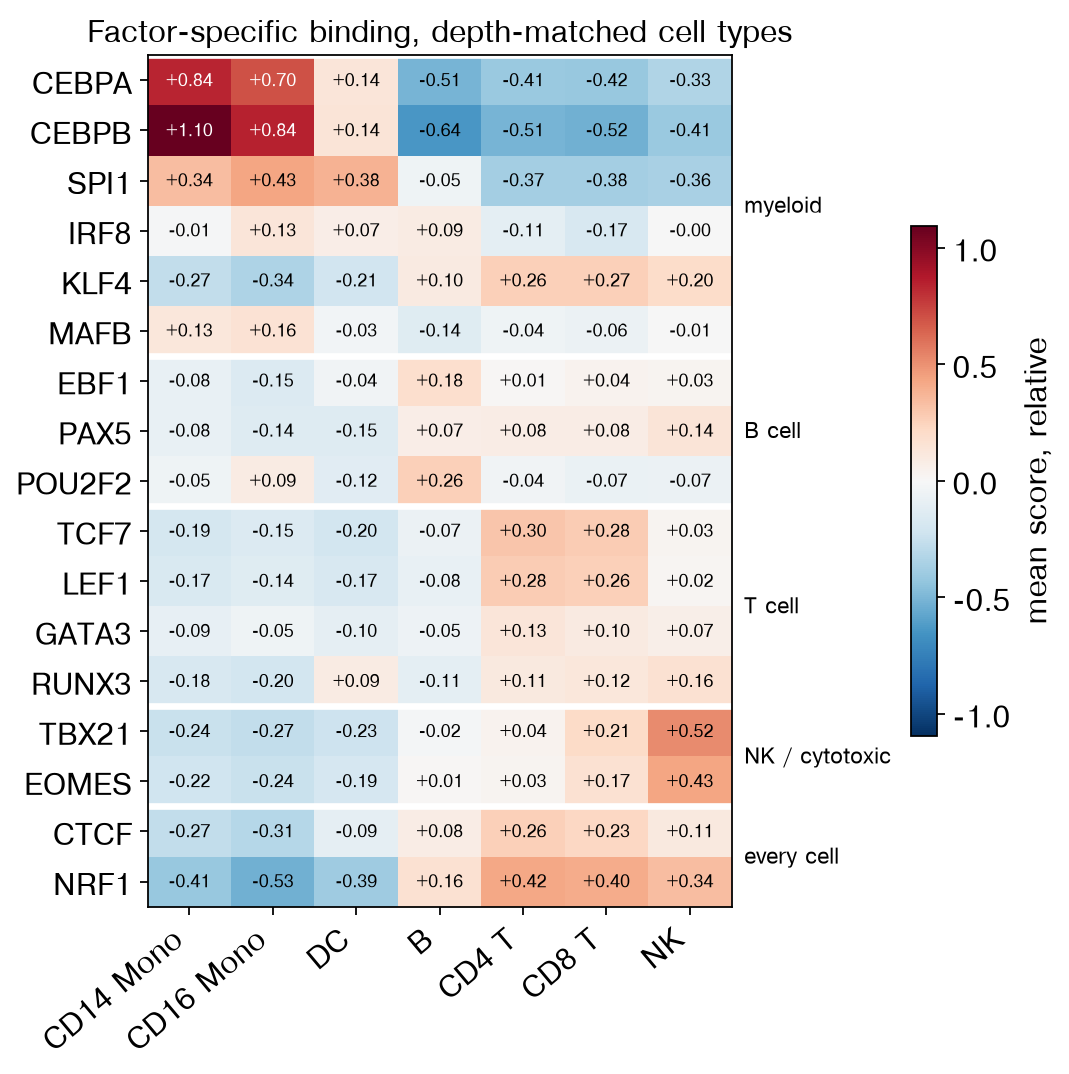

In [6]:
C = S.sub(S.mean(1), axis=0)                                  # each site, relative to its mean
C = C - C.mean(0)                                             # each cell type, relative to all sites
M = C.groupby(sites['tf'].to_numpy()).mean().reindex(TFS)

fig, ax = plt.subplots(figsize=(7.2, 7))
vm = np.abs(M.to_numpy()).max()
im = ax.imshow(M.to_numpy(), cmap='RdBu_r', vmin=-vm, vmax=vm, aspect='auto')
ax.set_xticks(range(len(TYPES)), TYPES, rotation=40, ha='right')
ax.set_yticks(range(len(TFS)), TFS)
for i in range(len(TFS)):
    for j in range(len(TYPES)):
        ax.text(j, i, f'{M.iat[i, j]:+.2f}', ha='center', va='center', fontsize=8,
                color='w' if abs(M.iat[i, j]) > 0.6 * vm else 'k')
y = 0
for lin, tfs in PANEL.items():
    ax.axhline(y - 0.5, color='w', lw=3)
    ax.text(len(TYPES) - 0.35, y + (len(tfs) - 1) / 2, lin, va='center', fontsize=10)
    y += len(tfs)
fig.colorbar(im, ax=ax, shrink=0.6, pad=0.2, label='mean score, relative')
ax.set_title('Factor-specific binding, depth-matched cell types')
plt.show()

Each lineage's factors are bound in that lineage:

* **myeloid**: C/EBPα and β are the strongest signal of the panel (+0.70 to +1.10 in
  the two monocyte types, −0.33 to −0.64 in lymphocytes); PU.1 (SPI1) is bound in
  monocytes and DCs (+0.34 to +0.43) and not in T and NK cells (about −0.37); MAFB
  slightly in monocytes;
* **B cells**: OCT2 (POU2F2, +0.26) and EBF1 (+0.18) are highest in B cells;
* **T cells**: TCF7 and LEF1 in CD4 and CD8 T cells (+0.26 to +0.30), GATA3 most in
  CD4 T cells (+0.13);
* **NK and cytotoxic T cells**: T-bet (TBX21) and EOMES in NK cells (+0.52, +0.43)
  and, less, in CD8 T cells (+0.21, +0.17).

Not every factor separates. PAX5 (2,482 sites, a long, degenerate motif) and IRF8
barely differ between cell types. The two controls, CTCF and NRF1, are not flat
either: they sit lower in myeloid cells and higher in lymphocytes, as does KLF4,
whose GC-rich motif sits mostly in promoters. Myeloid cells open many distal
elements, so relative to all candidate sites their constitutive sites rank lower.
Read a factor's row against these controls.

## Part 6 · Sites bound in one cell type and not another

The heatmap averages thousands of sites. Site by site, compare two cell types:
each dot is one motif site, its position the score in the two cell types. A
difference of 1 is an e-fold (2.7×) difference in occupancy; the percentages count
sites beyond ±1. CTCF, bound everywhere, is the control: one CTCF panel for each
pair of cell types compared.

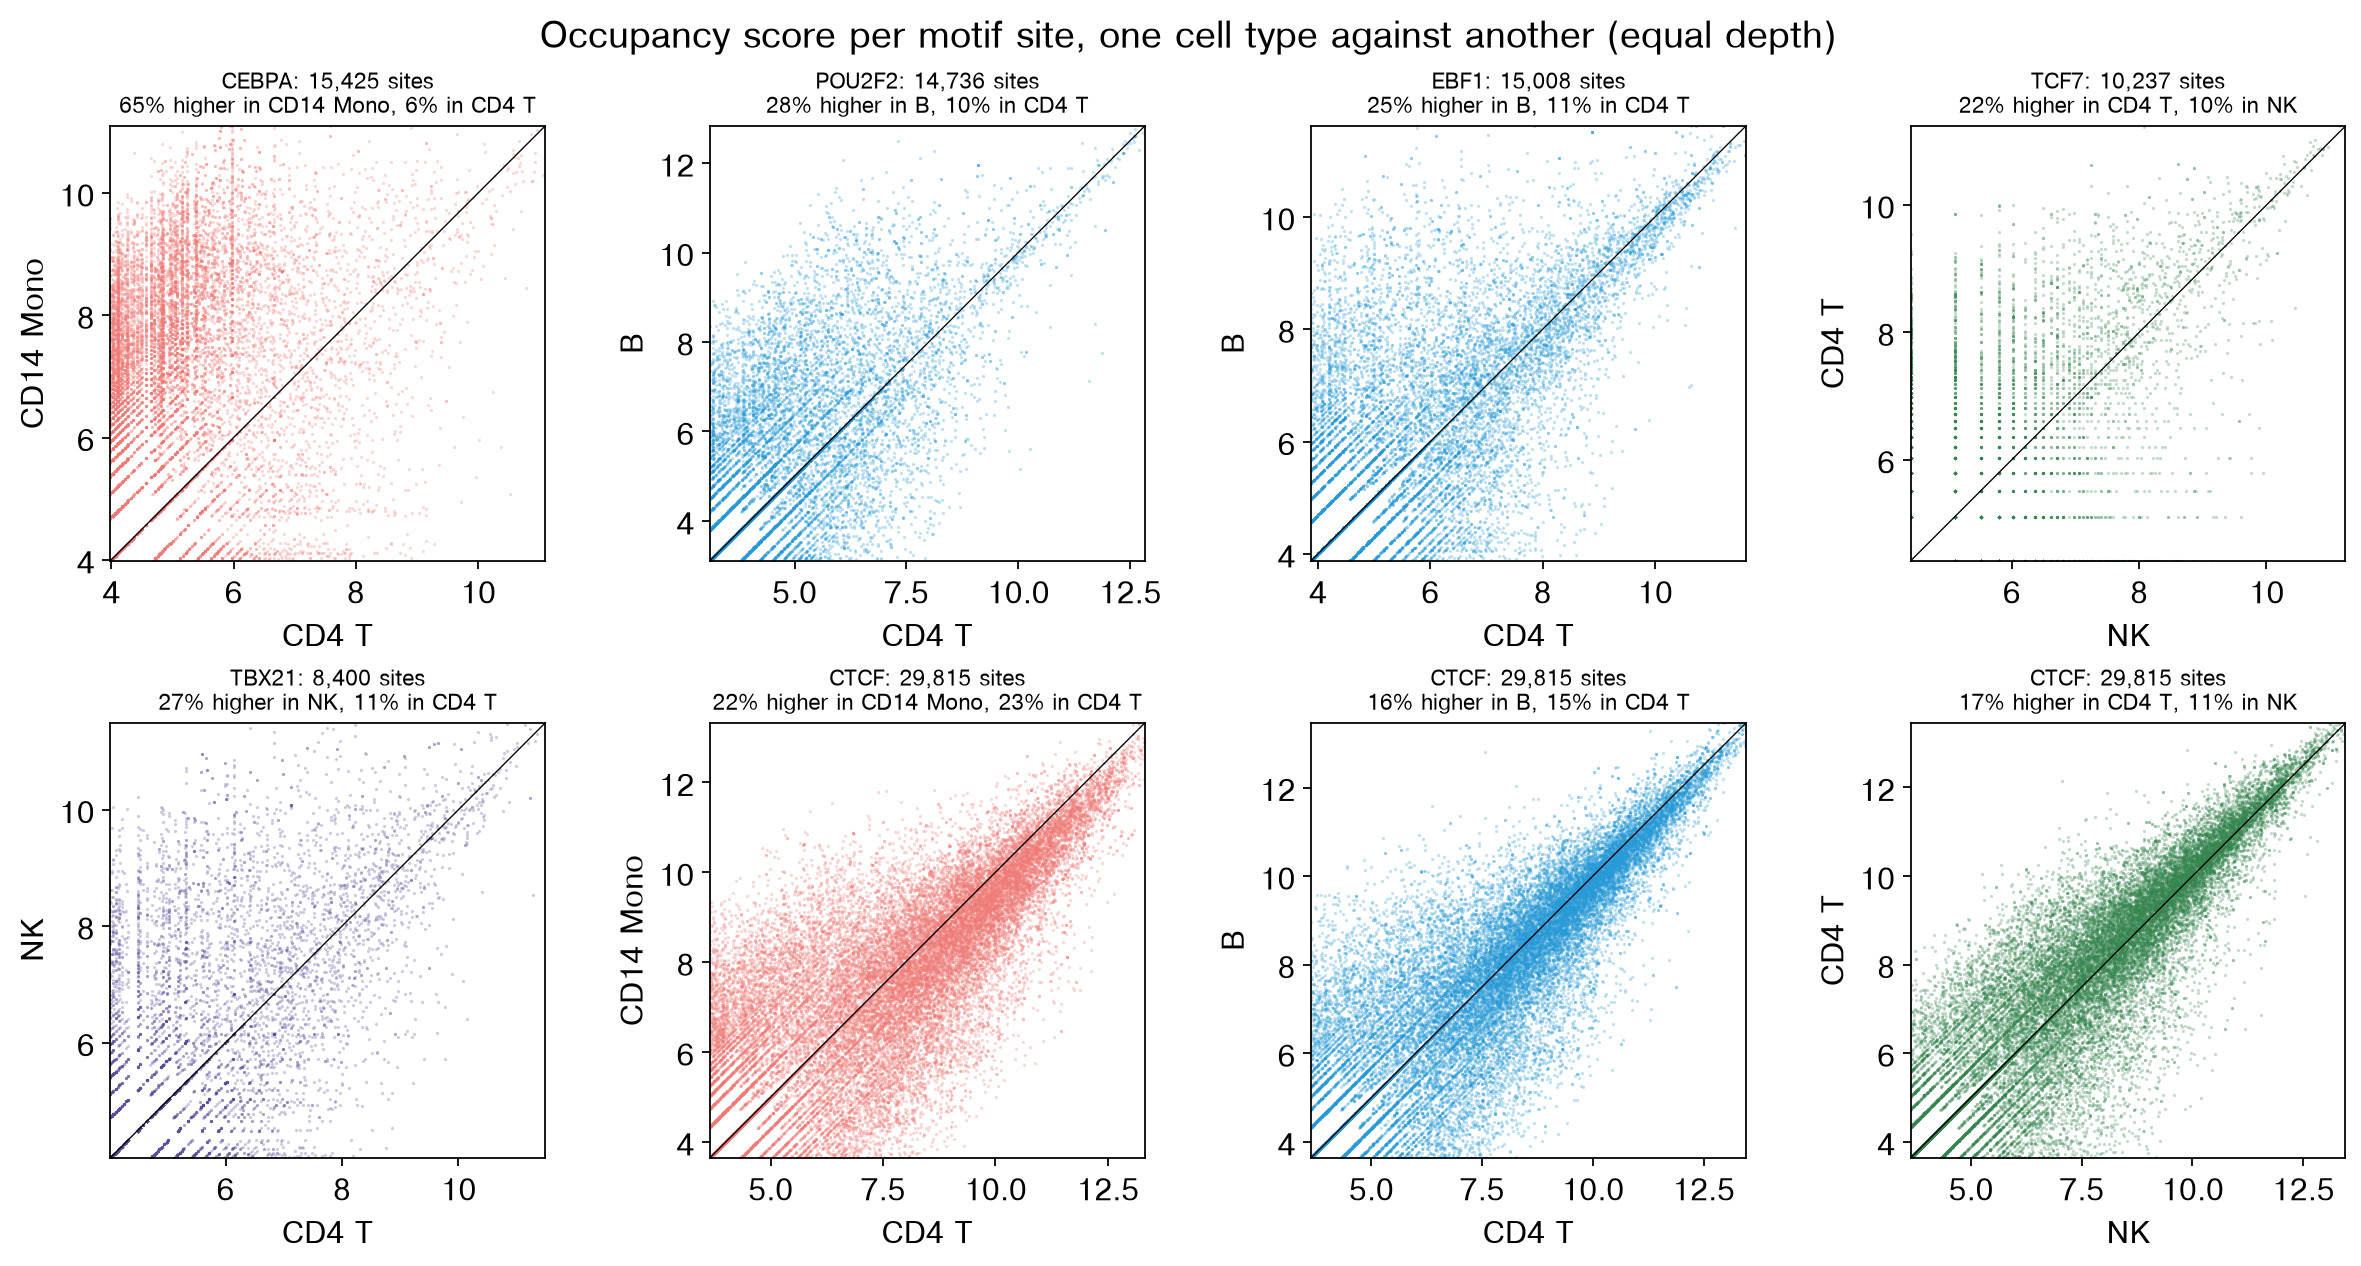

In [7]:
PAIRS = [('CEBPA', 'CD4 T', 'CD14 Mono'), ('POU2F2', 'CD4 T', 'B'), ('EBF1', 'CD4 T', 'B'),
         ('TCF7', 'NK', 'CD4 T'), ('TBX21', 'CD4 T', 'NK'),
         ('CTCF', 'CD4 T', 'CD14 Mono'), ('CTCF', 'CD4 T', 'B'), ('CTCF', 'NK', 'CD4 T')]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.8), layout='constrained')
for ax, (tf, a, b) in zip(axes.ravel(), PAIRS):
    m = (sites['tf'] == tf).to_numpy()
    x, y = S.loc[m, a].to_numpy(), S.loc[m, b].to_numpy()
    ax.scatter(x, y, s=2, lw=0, alpha=0.3, color=TCOL[b], rasterized=True)
    lo, hi = np.percentile(np.r_[x, y], [0.5, 99.9])
    ax.plot([lo, hi], [lo, hi], color='k', lw=0.6)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
    ax.set_xlabel(a); ax.set_ylabel(b)
    ax.set_title(f'{tf}: {m.sum():,} sites\n{np.mean(y - x > 1):.0%} higher in {b}, '
                 f'{np.mean(x - y > 1):.0%} in {a}', fontsize=10)
fig.suptitle('Occupancy score per motif site, one cell type against another (equal depth)')
plt.show()

The site-level picture agrees, measured against CTCF for the same two cell types
(where 11-23% of sites differ by more than an e-fold each way):

* **CEBPA**: 65% of its sites are more bound in CD14 monocytes than in CD4 T cells,
  6% the other way;
* **POU2F2** and **EBF1**: 28% and 25% more bound in B cells than in CD4 T cells,
  10-11% the other way;
* **TCF7**: 22% more bound in CD4 T cells than in NK cells and 10% the other way,
  although CTCF leans towards CD4 T cells only slightly (17% vs 11%);
* **T-bet (TBX21)**: 27% more bound in NK cells than in CD4 T cells and 11% the
  other way, against CTCF's lean the other way.

The stripes are sites with few cuts: at 7.5 M counts per cell type, many sites have
0, 1 or 2 insertions in one of the two, and the score takes a few discrete values.

Which genes do these sites regulate? A first answer is the nearest protein-coding
gene (GENCODE v41 TSS, within 50 kb). For each factor, the 300 sites most bound in
its cell type relative to the other cell type, and the genes most often nearest:

In [8]:
%%time
rows = []
with gzip.open(str(epi.data.hg38.annotation), 'rt') as fh:          # GENCODE v41, downloaded once
    for line in fh:
        if '\tgene\t' in line and 'gene_type=protein_coding' in line:
            f = line.split('\t')
            rows.append((f[0], int(f[3]) - 1 if f[6] == '+' else int(f[4]) - 1,
                         re.search(r'gene_name=([^;]+)', f[8]).group(1)))
tss = pd.DataFrame(rows, columns=['chrom', 'tss', 'gene']).sort_values(['chrom', 'tss'])

centre = ((sites['start'] + sites['end']) // 2).to_numpy()
sites['gene'], sites['distance'] = None, np.inf
for ch, g in tss.groupby('chrom'):
    m = (sites['chrom'] == ch).to_numpy()
    if m.any():
        t = g['tss'].to_numpy()
        j = np.clip(np.searchsorted(t, centre[m]), 1, len(t) - 1)
        j = np.where(np.abs(t[j - 1] - centre[m]) <= np.abs(t[j] - centre[m]), j - 1, j)
        sites.loc[m, 'gene'] = g['gene'].to_numpy()[j]
        sites.loc[m, 'distance'] = np.abs(t[j] - centre[m])

table = {}
for tf, a, b in PAIRS[:5]:
    m = (sites['tf'] == tf).to_numpy() & (sites['distance'] < 50_000).to_numpy()
    d = (S.loc[m, b] - S.loc[m, a]).sort_values(ascending=False)
    genes = sites.loc[d.index[:300], 'gene'].value_counts()
    table[f'{tf}, {b} vs {a}'] = ', '.join(genes.index[:15])
with pd.option_context('display.max_colwidth', None):
    display(pd.Series(table, name='nearest genes of the 300 most cell-type-specific sites').to_frame())

,nearest genes of the 300 most cell-type-specific sites
"CEBPA, CD14 Mono vs CD4 T","WSB1, ANO10, HMGCR, LITAF, ST14, IQGAP3, RIN2, MFSD2A, TLR4, MAN1A1, HAAO, MCFD2, SIGLEC10, FXYD2, ZDHHC20"
"POU2F2, B vs CD4 T","SIPA1L1, CAMK2B, FCRL3, TLE1, FCRL5, OSBPL8, TNFSF9, GNG7, CD82, CARM1, ENSG00000285446, CPLX3, TTF1, MRPS18A, RBM6"
"EBF1, B vs CD4 T","DENND3, LILRA4, WNT7B, PMEPA1, CD82, TNFSF9, NKX6-3, CLEC17A, PXDC1, TNFRSF13C, DOK7, B3GNT7, VASN, CCR6, ENSG00000259753"
"TCF7, CD4 T vs NK","RCAN3, TSHZ2, RTKN2, DDX3X, VSIR, CRTC3, MFHAS1, PKIG, CHRNA1, RASSF2, DCT, CYP2B6, DDX51, CLPB, CD40LG"
"TBX21, NK vs CD4 T","ZNF512, TRMU, NFIX, GZMB, OGFOD2, IL12RB2, ABHD2, GFPT2, ACP1, SETD3, KIR3DL1, SUPT4H1, HYDIN, AMN1, PYHIN1"


CPU times: user 2.33 s, sys: 16 ms, total: 2.35 s
Wall time: 2.35 s


The nearest genes of each factor's most cell-type-specific sites include markers
of that cell type: *TLR4*, *LITAF* and *SIGLEC10* for C/EBPα in monocytes; *FCRL3*,
*FCRL5* and *CD82* for OCT2 and *TNFRSF13C* (BAFF receptor), *CLEC17A* and *CCR6*
for EBF1 in B cells; *CD40LG*, *TSHZ2* and *RCAN3* for TCF7 in CD4 T cells; *GZMB*,
*IL12RB2*, *KIR3DL1* and *PYHIN1* for T-bet in NK cells. The nearest gene is only a
first guess at a site's target; [t_peak_to_gene](t_peak_to_gene.ipynb) links peaks
to genes with expression.

## Summary

| | |
|---|---|
| Call | `epi.tl.tf_binding(adata, motif_sites, motif_key='tf', groupby='celltype')`: one score per site and cell type, in seconds |
| Score | log Σ over the factor's sites within ±150 bp of accessibility × exp(β · motif score); no training, no bias model |
| Depth | scores grow with depth: compare cell types at matched depth (Part 4) |
| Here | 17 factors, 289k candidate sites, seven PBMC cell types; lineage factors are bound in their lineages (Parts 5-6) |
| Evaluation | ChIP-seq AUROC in four ENCODE cell types: `tests/parity/tf_binding/` |
| Footprints | PRINT's footprint-based score is `method='print'` ([t_print_footprint](t_print_footprint.ipynb)); from sequence, per cell type: [t_seq2print](t_seq2print.ipynb) |